# Clasificación de imágenes médicas con CNNs
## A - Objetivo

Desarrollar un método basado en redes neuronales convolucionales que permita clasificar con exactitud imágenes extraidas de MRIs en una de 4 categorias. (Glioma, meningioma, pituitary y tejido sano)

## B - Conjunto de datos

Los datos corresponden a un dataset de 7023 imágenes extraídas de MRIs tomados
desde distintos ángulos y disponibles para dominio público. El dataset es accesible
en el siguiente enlace.

In [1]:
import os

for clase in sorted(os.listdir('archive')):
    ruta = os.path.join('archive', clase)
    if os.path.isdir(ruta):
        print(f"{clase}: {len(os.listdir(ruta))} imágenes")


glioma: 1621 imágenes
healthy: 2000 imágenes
meningioma: 1645 imágenes
pituitary: 1757 imágenes


## C - Actividades por realizar
1. Preparación de las imágenes para el entrenamiento y prueba del modelo.
Construya un pipeline para cargar las imágenes y dividirlas en conjuntos de
entrenamiento y prueba.
2. Desarrollo de la arquitectura de red neuronal convolucional para clasificación
de las imágenes de MRI en una de las 4 categorías. La arquitectura es de libre
elección, se recomienda utilizar bloques de convolución y max pooling o usar
redes existentes y hacerles finetunning para este problema.

### 1. Librerias
Importación de librerias torch para crear los modelos de redes neuronales artificiales.

In [2]:
#Importamos las librerias requeridas
##Importamos pytorch von lod mofulod para construir redes neuronales

import copy
import torch
import torch.nn as nn
import torchvision
from torchvision.transforms import v2
from torch.utils.data import DataLoader, random_split
import torch.optim as optim      # Optimizadores de PyTorch

#Importamos pandas y numpy para trabajar los datos matriciales
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

#Inicializamos las semillas
torch.manual_seed(42)
np.random.seed(42)

#Se define el uso de GPU y cuda para el procesamiento de las redes convolucionales
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Usando dispositivo: {device}')

Usando dispositivo: cpu


### 2. Preparación y preprocesamineto de imagenes

#### Variables globales

Definimos las variables gloables que usaremos durante todo el modelo.
1) El tamaño de 224 pixeles,usado, si bien no esta definido en la documentación de pytorch, según el bot de chatmigo, es una convención utilizada en modelos CNN. 
2) Para el tamaño del batch se tomo el valor de 32 ya que un batch mas pequeño puede ser mas lento, y un valor mas grande puede consumir mas recursos computacionales.

In [3]:
#Definición de las variables globales
category = ["glioma","healthy","meningioma","pituitary"]
img_size = (224,224)
batch_size = 32
seed = 42

#### Pipeline de transformación

Definimos el pipeline para la transformación de imagenes
1) Cambio de tamaño usando la variable global de img_size
2) Transformamos los datos en tensores para poder trabajar con ellos en las CNN´s
3) Aplicamos una normalización de los datos para estabilizar los datos de entrenamiento, convirtiendo los valores de los pixeles en un rango de 0 a 1

In [4]:
import torchvision.transforms as transforms

transform = transforms.Compose([
    transforms.Resize(img_size),  # Ajusta a 224x224 píxeles
    transforms.ToTensor(),
    #transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

#### Carga y división de los datos

1) Realizamos la carga de las imagenes en la variable dataset
2) Realizamos la división de los datos

In [5]:
#Se realiza la carga de los datos, usando la función Image Folder
#Y nuestro previemente definido pipelin de tranformación.
dataset = torchvision.datasets.ImageFolder(root='archive', transform=transform)

#Se definen los tamaños de los conjuntos train,validaiton y test.
total_size = len(dataset)
train_size = int(0.8 * total_size)
val_size   = int(0.1 * total_size)
test_size  = total_size - train_size - val_size

#Se realiza la divsión de los datos.
trainset,valset,testset = random_split(
    dataset,
    [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(seed)
)

In [6]:
#Se crean los DataLoaders, solo el de train se revuelve
train_loader = DataLoader(trainset, batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(valset,   batch_size=batch_size, shuffle=False)
test_loader  = DataLoader(testset,  batch_size=batch_size, shuffle=False)

print(f'Imagenes train: {len(trainset)}, validación: {len(valset)}, test: {len(testset)}')

Imagenes train: 5618, validación: 702, test: 703


Como las imagenes se leen desde las carpetas con ImageFolder, se usan DataLoaders para ir cargandolas por batches. Se crea uno para train, uno para validación y uno para test, y solo el de train se revuelve (shuffle) para que los batches cambien en cada epoca.

#### Función de visualización de instancias

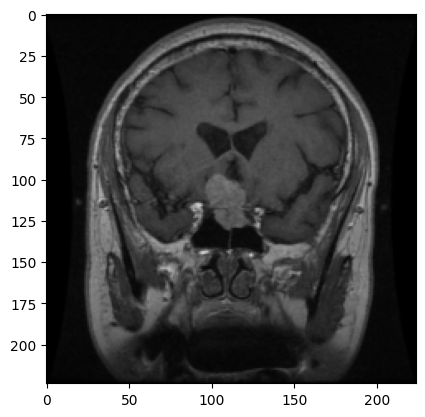

In [7]:
# Funcion para mostrar una imagen
def imshow(img):
    img = img / 2 + 0.5     # unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()


# algunas imagenes de entrenamiento
dataiter = iter(trainset)
images, labels = next(dataiter)
# show images
imshow(torchvision.utils.make_grid(images))


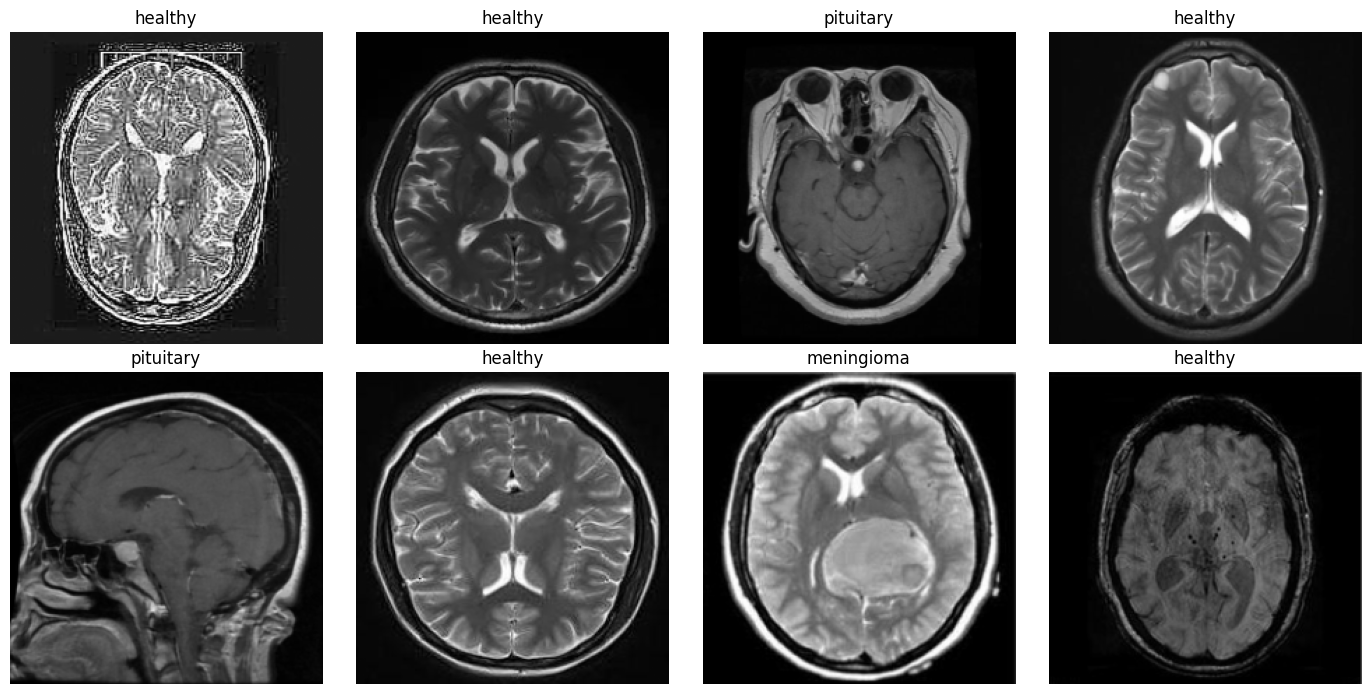

In [8]:
def imshow(images, labels, n_imagenes=8, n_columnas=4):
    """
    Muestra varias imagenes de un batch con su clase como titulo.
    Entrada:
    images = tensor de imagenes de forma (batch, 3, alto, ancho)
    labels = tensor con la clase de cada imagen
    n_imagenes = cantidad de imagenes a mostrar
    n_columnas = numero de columnas de la grilla
    Salida:
    Grilla con las imagenes
    """
    n_imagenes = min(n_imagenes, len(images))
    n_filas = int(np.ceil(n_imagenes / n_columnas))
    fig, axes = plt.subplots(n_filas, n_columnas, figsize=(3.5 * n_columnas, 3.5 * n_filas))
    axes = np.array(axes).flatten()

    for k, ax in enumerate(axes):
        ax.axis('off')
        if k >= n_imagenes:
            continue
        img = images[k] / 2 + 0.5     #se quita la normalización para mostrar la imagen
        ax.imshow(np.transpose(img.numpy(), (1, 2, 0)))
        ax.set_title(category[labels[k]], fontsize=12)

    plt.tight_layout()
    plt.show()


#Se toma un batch del train_loader (trainset devuelve una sola imagen a la vez)
dataiter = iter(train_loader)
images, labels = next(dataiter)
imshow(images, labels, n_imagenes=8)

### 3. Arquitectura de la red

Se define la función load_model() que es la que arma la red convolucional. La red tiene dos partes, una primera parte de extracción de caracteristicas (los bloques convolucionales) y una segunda parte de clasificación (las capas densas).

##### 3.1. Bloques convolucionales

Usamos 4 bloques iguales, y cada bloque tiene las siguientes capas en este orden:
1) **Conv2d con kernel de 3x3 y padding=1:** es la capa que aprende los filtros. Se usó kernel de 3x3 porque es el mas comun y con padding=1 la imagen no pierde tamaño en la convolución, solo cambia el numero de canales.
2) **BatchNorm2d:** normaliza la salida de la convolución en cada batch. Se agregó porque ayuda a que el entrenamiento sea mas estable y a que la red converja mas rapido.
3) **ReLU:** función de activación, deja los valores positivos y pone en 0 los negativos. Es lo que le da la no linealidad a la red.
4) **MaxPool2d de 2x2:** se queda con el valor maximo de cada ventana de 2x2, entonces reduce el alto y el ancho de la imagen a la mitad. 

En cada bloque se duplica el numero de filtros (16, 32, 64 y 128). La idea es que los primeros bloques aprendan cosas simples como bordes y texturas, y los ultimos bloques aprendan formas mas complejas como la forma del tumor. Como la imagen se va haciendo mas pequeña, podemos usar mas filtros sin que el costo computacional suba mucho.

La imagen entra a la red con 3 canales (RGB) y un tamaño de 224x224. En cada bloque la convolución cambia el número de canales y el maxpool reduce el alto y el ancho a la mitad. Por eso después del primer bloque queda de 16x112x112, después del segundo de 32x56x56, después del tercero de 64x28x28 y al final del cuarto bloque queda de 128x14x14. Esto es lo que después se aplana y pasa al clasificador.

##### 3.2. Clasificador

Al final del ultimo bloque la imagen queda como un bloque de 128x14x14, pero las capas densas solo reciben vectores. Se usa primero un pooling promedio global AdaptiveAvgPool2d, que promedia cada uno de los 128 mapas de características y deja un solo valor por filtro (128x1x1). Después Flatten solo cambia la forma a un vector de 128 valores. Con esto la parte densa tiene muchos menos parámetros, lo que reduce el riesgo de sobreajuste, y la red ya no depende del tamaño de la imagen de entrada. 

Ese vector pasa a una capa densa de 256 neuronas con ReLU, que es la que junta todas las características que encontraron los filtros. Después de esta capa se pone un Dropout de 0.5, que en cada paso del entrenamiento apaga al azar la mitad de las neuronas. Se agregó porque solo hay 7.000 imágenes y sin esto la red se podría aprender de memoria las imágenes de entrenamiento. Por último está la capa de salida con 4 neuronas, una para cada categoría (glioma, healthy, meningioma y pituitary). No se usó softmax porque nn.CrossEntropyLoss, la función de pérdida que se va a usar ya lo aplica.así que primero se usa Flatten para convertirlo en un vector. Ese vector pasa a una capa densa de 256 neuronas con ReLU, que es la que junta todas las características que encontraron los filtros. Después de esta capa se pone un Dropout de 0.5, que en cada paso del entrenamiento apaga al azar la mitad de las neuronas. Se agregó porque solo hay 7.000 imágenes y sin esto la red se podría aprender de memoria las imágenes de entrenamiento. Por último está la capa de salida con 4 neuronas, una para cada categoría (glioma, healthy, meningioma y pituitary). No se usó softmax porque nn.CrossEntropyLoss, la función de pérdida que se va a usar ya lo aplica.



In [9]:
def load_model(num_classes=len(category)):
    """
    Función que construye el modelo de red neuronal convolucional para
    clasificar las imagenes de MRI en las 4 categorias.
    Entrada:
    num_classes = numero de clases, por defecto son 4 (tamaño de category)
    Salida:
    model = modelo CNN en pytorch
    """

    #No se pone softmax al final porque la funcion nn.CrossEntropyLoss ya lo hace
    model = nn.Sequential(
        #Bloque 1: entran las imagenes con 3 canales (RGB) y sacamos 16 filtros
        nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, padding=1),
        nn.BatchNorm2d(16),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2),    #224x224 pasa a 112x112

        #Bloque 2: 32 filtros
        nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1),
        nn.BatchNorm2d(32),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2),    #112x112 pasa a 56x56

        #Bloque 3: 64 filtros
        nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
        nn.BatchNorm2d(64),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2),    #56x56 pasa a 28x28

        #Bloque 4: 128 filtros
        nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, padding=1),
        nn.BatchNorm2d(128),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2),    #28x28 pasa a 14x14

        #Pooling global: promedia cada mapa de caracteristicas (14x14) en un solo valor,
        #asi la salida pasa de 128x14x14 a 128x1x1
        nn.AdaptiveAvgPool2d(1),

        #Se aplana la salida para pasarla a las capas densas (128x1x1 pasa a 128)
        nn.Flatten(),

        #Capa densa de 256 neuronas, el tamaño de entrada es 128 (un valor por filtro)
        #(version anterior, con Flatten directo: nn.Linear(128 * (img_size[0] // 16) * (img_size[1] // 16), 256))
        nn.Linear(128, 256),
        nn.ReLU(),
        nn.Dropout(p=0.5),   #apagamos la mitad de las neuronas para evitar sobreajuste

        #Capa de salida con una neurona por cada categoria
        nn.Linear(256, num_classes)
    )

    return model


#Se prueba el modelo con un batch de datos aleatorios para revisar que la salida
#tenga el tamaño correcto (batch_size, 4)
model = load_model().to(device)
print(model)
print(f'Numero de parametros: {sum(p.numel() for p in model.parameters()):,}')

model.eval()    #modo evaluación para que la prueba no altere las estadisticas de BatchNorm
with torch.no_grad():
    salida = model(torch.randn(batch_size, 3, *img_size, device=device))
model.train()
print(f'Tamaño de la salida: {tuple(salida.shape)}')

Sequential(
  (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): ReLU()
  (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (6): ReLU()
  (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (10): ReLU()
  (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (12): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (13): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (14): ReL

### 4. Entrenamiento del modelo

En cada epoca el modelo se entrena con train y se evalua con validación. El conjunto de test no se toca en el entrenamiento, se deja para la evaluación final. Tambien se van guardando los pesos de la epoca con menor perdida en validación, asi al final nos quedamos con el mejor modelo y no con el de la ultima epoca, que puede estar sobreajustado.

In [10]:
def evaluate_model(model, loader, criterion=None):
    """
    Evalua el modelo sobre un DataLoader y calcula la perdida y la precisión promedio.
    Basada en la funcion evaluate_model del laboratorio CNN2.
    Entrada:
    model = modelo de pytorch
    loader = DataLoader con las imagenes a evaluar
    criterion = funcion de perdida (por defecto nn.CrossEntropyLoss)
    Salida:
    loss = perdida promedio
    accuracy = precisión promedio
    """
    if criterion is None:
        criterion = nn.CrossEntropyLoss()

    #Se pone el modelo en modo evaluación para que el Dropout no apague neuronas
    #y el BatchNorm usa los valores que aprendio en el entrenamiento
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)

            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)

            total_loss += loss.item() * len(X_batch)
            correct += (outputs.argmax(dim=1) == y_batch).sum().item()
            total += len(X_batch)

    return total_loss / total, correct / total


def train_model(model, train_loader, val_loader, optimizer, epochs=10, criterion=None,
                scheduler=None, patience=None, min_delta=1e-4):
    """
    Entrena el modelo por un numero de epocas y en cada epoca lo evalua con el
    conjunto de validación. Basada en la funcion train_model del laboratorio CNN2,
    con scheduler y parada temprana agregados.
    Entrada:
    model = modelo de pytorch
    train_loader = DataLoader de entrenamiento
    val_loader = DataLoader de validación
    optimizer = optimizador de torch.optim
    epochs = numero maximo de epocas
    criterion = funcion de perdida (por defecto nn.CrossEntropyLoss)
    scheduler = scheduler de torch.optim.lr_scheduler (opcional). Si es
                ReduceLROnPlateau se actualiza con la perdida de validación
    patience = epocas sin mejorar antes de parar el entrenamiento (None = no para)
    min_delta = mejora minima de la perdida de validación para contarla
    Salida:
    history = diccionario con 'accuracy', 'val_accuracy', 'loss', 'val_loss' y 'lr'
    """
    if criterion is None:
        criterion = nn.CrossEntropyLoss()

    model.to(device)
    history = {'accuracy': [], 'val_accuracy': [], 'loss': [], 'val_loss': [], 'lr': []}

    #Variables para guardar el mejor modelo (el de menor perdida en validación)
    best_val_loss = float('inf')
    best_weights = copy.deepcopy(model.state_dict())
    best_epoch = 0
    sin_mejora = 0

    for epoch in range(epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0

        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)

            optimizer.zero_grad()
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * len(X_batch)
            correct += (outputs.argmax(dim=1) == y_batch).sum().item()
            total += len(X_batch)

        train_loss, train_acc = running_loss / total, correct / total
        val_loss, val_acc = evaluate_model(model, val_loader, criterion)

        #El scheduler se actualiza una vez por epoca, despues de validar
        if scheduler is not None:
            if isinstance(scheduler, torch.optim.lr_scheduler.ReduceLROnPlateau):
                scheduler.step(val_loss)
            else:
                scheduler.step()
        lr_actual = optimizer.param_groups[0]['lr']

        history['accuracy'].append(train_acc)
        history['val_accuracy'].append(val_acc)
        history['loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['lr'].append(lr_actual)

        #Si la perdida en validación mejoro (al menos min_delta) se guardan los pesos de esta epoca
        if val_loss < best_val_loss - min_delta:
            best_val_loss = val_loss
            best_weights = copy.deepcopy(model.state_dict())
            best_epoch = epoch + 1
            sin_mejora = 0
        else:
            sin_mejora += 1

        print(f"Epoch {epoch + 1}/{epochs} - loss: {train_loss:.4f} - accuracy: {train_acc:.4f} "
              f"- val_loss: {val_loss:.4f} - val_accuracy: {val_acc:.4f} - lr: {lr_actual:.2e}")

        #Parada temprana
        if patience is not None and sin_mejora >= patience:
            print(f'Parada temprana: {patience} epocas sin mejorar la perdida en validación.')
            break

    #Al final se cargan los pesos del mejor modelo
    model.load_state_dict(best_weights)
    print(f'Se cargo el modelo de la epoca {best_epoch} con menor perdida en validación: {best_val_loss:.4f}')

    return history

Para entrenar se usa Adam con un learning rate inicial de 0.001, un maximo de 50 epocas, el scheduler ReduceLROnPlateau y parada temprana con paciencia de 8 epocas. Como se guarda el mejor modelo en validación, si en las ultimas epocas la red empieza a sobreajustar no se pierde el mejor resultado.

In [12]:
#Se crea el modelo y se entrena con Adam
model = load_model()
optimizer = optim.Adam(model.parameters(), lr=0.001)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min',
                                                 factor=0.3, patience=5, min_lr=1e-6)
resultsFit = train_model(model, train_loader, val_loader,
                         optimizer=optimizer,
                         epochs=30,
                         scheduler=scheduler,
                         patience=8)

Epoch 1/30 - loss: 0.7975 - accuracy: 0.6784 - val_loss: 0.8412 - val_accuracy: 0.6709 - lr: 1.00e-03
Epoch 2/30 - loss: 0.5854 - accuracy: 0.7691 - val_loss: 2.7241 - val_accuracy: 0.4943 - lr: 1.00e-03
Epoch 3/30 - loss: 0.5310 - accuracy: 0.7969 - val_loss: 0.7738 - val_accuracy: 0.6895 - lr: 1.00e-03
Epoch 4/30 - loss: 0.4885 - accuracy: 0.8184 - val_loss: 0.7480 - val_accuracy: 0.7222 - lr: 1.00e-03
Epoch 5/30 - loss: 0.4546 - accuracy: 0.8339 - val_loss: 0.5087 - val_accuracy: 0.8262 - lr: 1.00e-03
Epoch 6/30 - loss: 0.4195 - accuracy: 0.8386 - val_loss: 0.6683 - val_accuracy: 0.7422 - lr: 1.00e-03
Epoch 7/30 - loss: 0.4108 - accuracy: 0.8450 - val_loss: 0.3854 - val_accuracy: 0.8632 - lr: 1.00e-03
Epoch 8/30 - loss: 0.3808 - accuracy: 0.8542 - val_loss: 0.7067 - val_accuracy: 0.7251 - lr: 1.00e-03
Epoch 9/30 - loss: 0.3574 - accuracy: 0.8667 - val_loss: 1.3962 - val_accuracy: 0.6182 - lr: 1.00e-03
Epoch 10/30 - loss: 0.3599 - accuracy: 0.8596 - val_loss: 0.8850 - val_accuracy: 0

In [13]:
#Se guardan los pesos del mejor modelo para no tener que volver a entrenar
torch.save(model.state_dict(), 'mejor_modelo.pt')
print('Modelo guardado en mejor_modelo.pt')

#Para cargarlo despues:
#model = load_model().to(device)
#model.load_state_dict(torch.load('mejor_modelo.pt', map_location=device))


Modelo guardado en mejor_modelo.pt


### 5. Evaluación del modelo

En el laboratorio CNN2 el modelo se evaluaba solo con la precisión y las curvas de entrenamiento, pero pare este microproyecto no es suficiente porque son imagenes diagnosticas y no todos los errores pesan igual. El peor error es que el paciente tenga un tumor y el modelo diga que esta sano (falso negativo), porque se iria sin tratamiento. El caso contrario, decir que tiene un tumor cuando esta sano (falso positivo), tambien es un error, pero normalmente se descarta con otros examenes. Y confundir un tumor con otro, por ejemplo decir meningioma cuando es glioma, es menos grave que no detectarlo, pero sigue siendo importante porque cada tumor se trata diferente.

Por eso, ademas de la precisión, se revisan otras cosas. Todo se hace con el conjunto de test, que son imagenes que el modelo no vio en el entrenamiento:



1. **Curvas de precisión y pérdida por época**, como en el laboratorio, para detectar posible sobreajuste.
2. **Precisión y pérdida en test**, para medir el desempeño final con datos nuevos.
3. **Matriz de confusión**, para ver con qué clases se confunde el modelo.
4. **Métricas por clase:**
   - **Sensibilidad (recall):** de todas las imágenes de una clase, cuántas detectó el modelo. Es la más importante porque refleja los falsos negativos.
   - **Especificidad:** de las imágenes que no pertenecían a la clase, cuántas descartó correctamente.
   - **Valor predictivo positivo:** de las imágenes que el modelo asignó a la clase, cuántas realmente eran de ella. No lo llamamos "precisión" para no confundirlo con la precisión de las curvas.
   - **F1:** combina la sensibilidad y el valor predictivo positivo en un solo número.
5. **Tumor vs. sano:** se agrupan los tres tipos de tumor en una sola clase para evaluar qué tan bien detecta el modelo la presencia de un tumor, sin importar su tipo.
6. **Ejemplos de errores:** se muestran algunas imágenes mal clasificadas para entender en qué casos falla el modelo.



#### 5.1. Curvas de entrenamiento

Si la precisión de train sigue subiendo pero la de validación se queda quieta o empieza a bajar, el modelo se esta sobreajustando. La linea roja es el umbral de 90% que habia en el laboratorio, se dejo solo como referencia.

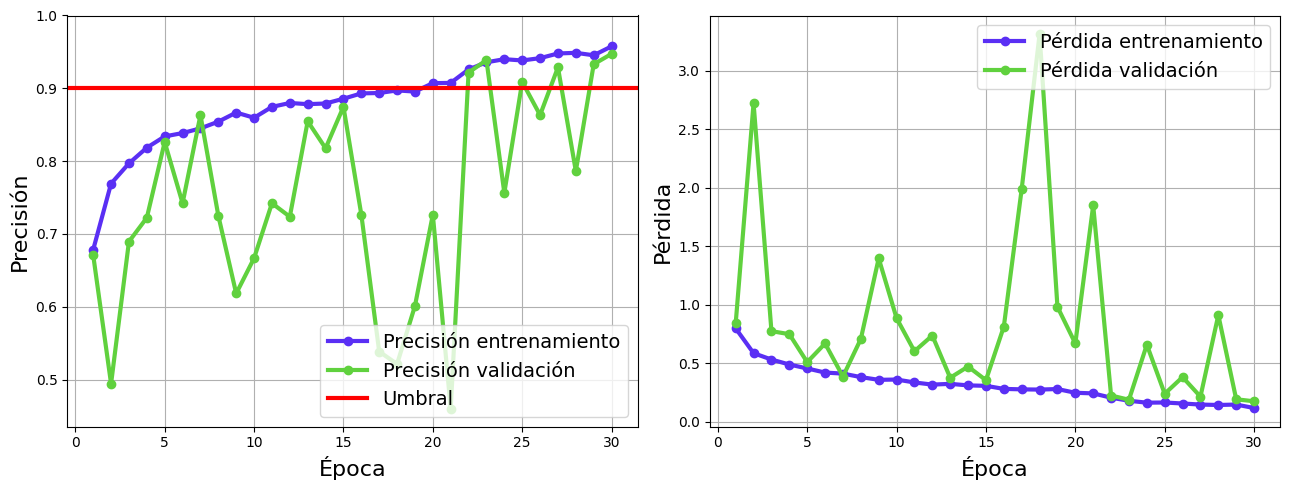

In [15]:
def visualization_history(resultsFit, umbral=0.9):
    """
    Grafica las curvas de precisión y perdida por epoca para entrenamiento y validación.
    Tomada del laboratorio CNN2.
    Entrada:
    resultsFit = historial del entrenamiento (diccionario con 'accuracy',
    'val_accuracy', 'loss' y 'val_loss')
    umbral = linea de referencia en la grafica de precisión
    Salida:
    Graficas de precisión y perdida
    """
    epocas = range(1, len(resultsFit['accuracy']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    #Grafica de precisión en entrenamiento y validación
    axes[0].plot(epocas, resultsFit['accuracy'], '#5a2ff4', linestyle='-', marker='o',
                 label='Precisión entrenamiento', lw=3)
    axes[0].plot(epocas, resultsFit['val_accuracy'], '#60d13e', linestyle='-', marker='o',
                 label='Precisión validación', lw=3)
    axes[0].axhline(umbral, color='red', lw=3, label='Umbral')
    axes[0].set_xlabel('Época', fontsize=16)
    axes[0].set_ylabel('Precisión', fontsize=16)
    axes[0].set_ylim(top=1)
    axes[0].grid()
    axes[0].legend(fontsize=14, loc='lower right')

    #Grafica de perdida en entrenamiento y validación
    axes[1].plot(epocas, resultsFit['loss'], '#5a2ff4', linestyle='-', marker='o',
                 label='Pérdida entrenamiento', lw=3)
    axes[1].plot(epocas, resultsFit['val_loss'], '#60d13e', linestyle='-', marker='o',
                 label='Pérdida validación', lw=3)
    axes[1].set_xlabel('Época', fontsize=16)
    axes[1].set_ylabel('Pérdida', fontsize=16)
    axes[1].grid()
    axes[1].legend(fontsize=14, loc='upper right')

    plt.tight_layout()
    plt.show()


visualization_history(resultsFit)

#### 5.2. Resultados en el conjunto de test

La precisión y la perdida en test se sacan con evaluate_model(), como en el laboratorio. Ademas se hizo la función get_predictions(), que guarda para cada imagen la clase real, la que predijo el modelo y las probabilidades, porque eso se necesita para la matriz de confusión y las demas metricas. Como el modelo no tiene softmax al final, se le aplica aqui para que las salidas queden como probabilidades.

In [16]:
def get_predictions(model, loader):
    """
    Obtiene las clases reales, las clases predichas y las probabilidades del modelo
    para todas las imagenes de un DataLoader.
    Entrada:
    model = modelo de pytorch ya entrenado
    loader = DataLoader con las imagenes (sin shuffle para mantener el orden)
    Salida:
    y_true = clases reales
    y_pred = clases predichas
    y_prob = probabilidades de cada clase, forma (N, 4)
    """
    model.eval()
    y_true, y_pred, y_prob = [], [], []
    with torch.no_grad():
        for X_batch, y_batch in loader:
            outputs = model(X_batch.to(device))
            #Se aplica softmax para pasar las salidas a probabilidades
            probs = torch.softmax(outputs, dim=1).cpu()

            y_true.append(y_batch)
            y_pred.append(probs.argmax(dim=1))
            y_prob.append(probs)

    return torch.cat(y_true).numpy(), torch.cat(y_pred).numpy(), torch.cat(y_prob).numpy()


#Se revisa que el orden de las clases de ImageFolder sea el mismo de la variable category
print(f'Clases del dataset: {dataset.classes}')

test_loss, test_acc = evaluate_model(model, test_loader)
print(f'Perdida en test: {test_loss:.4f}')
print(f'Precisión en test: {test_acc:.4f}')

y_true, y_pred, y_prob = get_predictions(model, test_loader)

Clases del dataset: ['glioma', 'healthy', 'meningioma', 'pituitary']
Perdida en test: 0.1532
Precisión en test: 0.9502


#### 5.3. Matriz de confusión

En la matriz las filas son la clase real y las columnas la clase que predijo el modelo, asi que la diagonal son los aciertos y todo lo demas son errores. Se hicieron dos, una con la cantidad de imagenes y otra normalizada por fila, en la que la diagonal ya es la sensibilidad de cada clase.

Lo que mas hay que mirar es la columna de healthy en las filas de los tumores, porque ahi estan los tumores que el modelo dijo que estaban sanos.

Tambien se puede ver si los errores tienen sentido. El glioma tiene bordes irregulares y el meningioma es un tumor bien delimitado que sale de las meninges, pero los dos pueden salir en zonas parecidas del cerebro, entonces puede que el modelo los confunda. El pituitary en cambio esta en la región selar, donde esta la hipofisis, entonces deberia ser mas facil de separar.

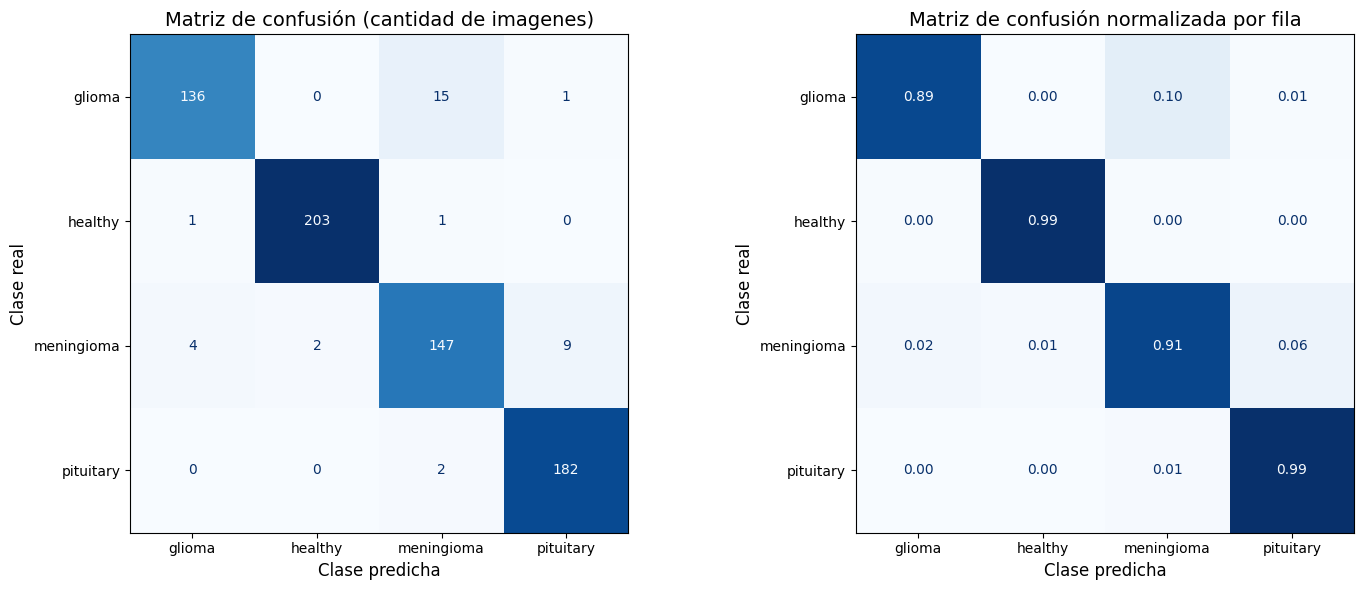

In [18]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

#Se pasan los labels para que la matriz siempre sea de 4x4 aunque una clase no se prediga nunca
cm = confusion_matrix(y_true, y_pred, labels=list(range(len(category))))
#Se normaliza por fila (cada fila suma 1) para ver el porcentaje de cada clase real
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

ConfusionMatrixDisplay(cm, display_labels=category).plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Matriz de confusión (cantidad de imagenes)', fontsize=14)

ConfusionMatrixDisplay(cm_norm, display_labels=category).plot(ax=axes[1], cmap='Blues',
                                                              colorbar=False, values_format='.2f')
axes[1].set_title('Matriz de confusión normalizada por fila', fontsize=14)

for ax in axes:
    ax.set_xlabel('Clase predicha', fontsize=12)
    ax.set_ylabel('Clase real', fontsize=12)

plt.tight_layout()
plt.show()

#### 5.4. Metricas por clase

Las metricas se calculan con la matriz de confusión. Para cada clase, los verdaderos positivos (VP) son las imagenes de esa clase que el modelo acerto, los falsos negativos (FN) son las de esa clase que puso en otra, los falsos positivos (FP) son las de otras clases que puso en esta, y los verdaderos negativos (VN) son todas las demas. Con eso:

- Sensibilidad = VP / (VP + FN)
- Especificidad = VN / (VN + FP)
- Valor predictivo positivo = VP / (VP + FP)
- F1 = 2 x (VPP x Sensibilidad) / (VPP + Sensibilidad)

La especificidad se calcula a mano porque sklearn no tiene una función para eso. En la ultima fila se pone el promedio de las 4 clases (macro), que le da el mismo peso a cada una.

In [19]:
#Se sacan VP, FN, FP y VN de cada clase usando la matriz de confusión
VP = np.diag(cm)
FN = cm.sum(axis=1) - VP     #los de la fila que no estan en la diagonal
FP = cm.sum(axis=0) - VP     #los de la columna que no estan en la diagonal
VN = cm.sum() - (VP + FN + FP)

sensibilidad  = VP / (VP + FN)
especificidad = VN / (VN + FP)
vpp           = VP / (VP + FP)
f1            = 2 * vpp * sensibilidad / (vpp + sensibilidad)

metricas = pd.DataFrame({
    'Sensibilidad (recall)': sensibilidad,
    'Especificidad': especificidad,
    'VPP (precision)': vpp,
    'F1-score': f1,
    'Imagenes en test': cm.sum(axis=1)
}, index=category)

#Se agrega el promedio macro de las 4 clases
metricas.loc['Promedio (macro)'] = metricas.iloc[:, :4].mean().tolist() + [cm.sum()]
metricas['Imagenes en test'] = metricas['Imagenes en test'].astype(int)

metricas.round(4)

,Sensibilidad (recall),Especificidad,VPP (precision),F1-score,Imagenes en test
glioma,0.8947,0.9909,0.9645,0.9283,152
healthy,0.9902,0.9960,0.9902,0.9902,205
meningioma,0.9074,0.9667,0.8909,0.8991,162
pituitary,0.9891,0.9807,0.9479,0.9681,184
Promedio (macro),0.9454,0.9836,0.9484,0.9464,703


#### 5.5. Tumor vs sano

Lo primero que importa en un diagnostico es saber si hay o no un tumor, por eso se juntan glioma, meningioma y pituitary en una sola clase "tumor" y se compara contra healthy. Se mide la sensibilidad para detectar tumor (de los pacientes con tumor cuantos detecto el modelo, lo ideal es que sea lo mas cercana a 1), la especificidad (de los sanos cuantos dijo bien que estaban sanos), el valor predictivo negativo o VPN (cuando el modelo dice sano, que tan seguido es cierto, que es justo el caso en que el paciente se iria para la casa) y cuantos tumores quedaron clasificados como healthy.

Sensibilidad para detectar tumor: 0.9960
Especificidad: 0.9902
Valor predictivo negativo (VPN): 0.9902
Falsos negativos (tumor clasificado como sano): 2 de 498 imagenes con tumor
Falsos positivos (sano clasificado como tumor): 2 de 205 imagenes sanas


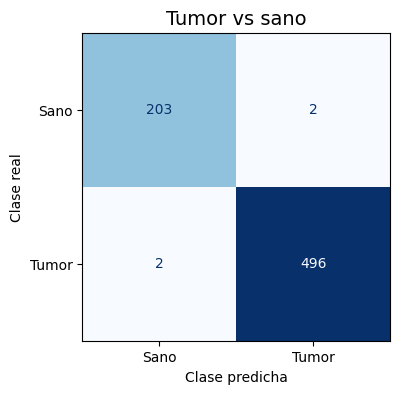

In [20]:
#Indice de la clase healthy en el dataset
idx_sano = dataset.class_to_idx['healthy']

#1 si tiene tumor (cualquiera de los 3), 0 si esta sano
tumor_real = (y_true != idx_sano).astype(int)
tumor_pred = (y_pred != idx_sano).astype(int)

cm_bin = confusion_matrix(tumor_real, tumor_pred, labels=[0, 1])
vn_b, fp_b, fn_b, vp_b = cm_bin.ravel()

sens_tumor = vp_b / (vp_b + fn_b)
espec_tumor = vn_b / (vn_b + fp_b)
vpn_tumor = vn_b / (vn_b + fn_b)

print(f'Sensibilidad para detectar tumor: {sens_tumor:.4f}')
print(f'Especificidad: {espec_tumor:.4f}')
print(f'Valor predictivo negativo (VPN): {vpn_tumor:.4f}')
print(f'Falsos negativos (tumor clasificado como sano): {fn_b} de {vp_b + fn_b} imagenes con tumor')
print(f'Falsos positivos (sano clasificado como tumor): {fp_b} de {vn_b + fp_b} imagenes sanas')

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm_bin, display_labels=['Sano', 'Tumor']).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Tumor vs sano', fontsize=14)
ax.set_xlabel('Clase predicha')
ax.set_ylabel('Clase real')
plt.show()

#### 5.6. Ejemplos mal clasificados

Por ultimo se muestran algunas imagenes de test en las que el modelo se equivoco, con la clase real, la que predijo y la probabilidad que le dio. Los tumores que quedaron como healthy salen primero y en rojo porque son los errores mas graves. Si el modelo se equivoca con una probabilidad alta, por ejemplo 0.95, quiere decir que estaba muy seguro de una respuesta mala, y eso es peor que equivocarse con una probabilidad baja.

Total de imagenes mal clasificadas: 35 de 703


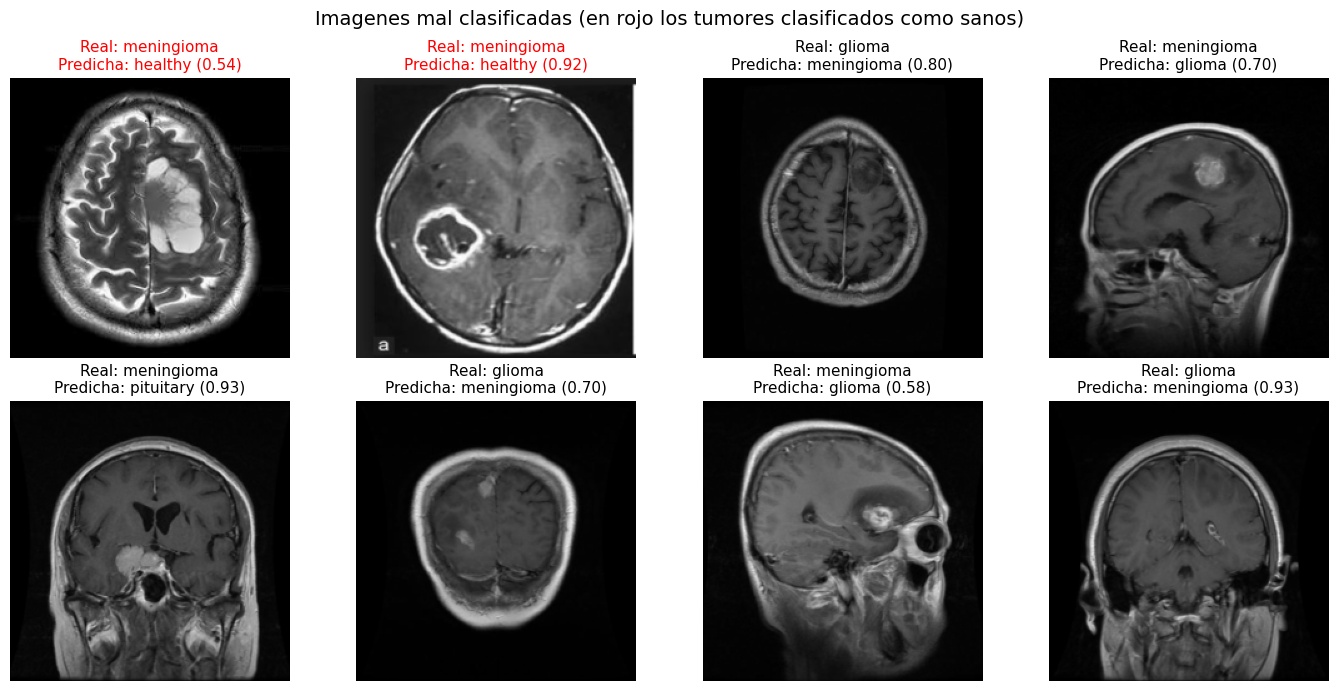

In [21]:
#Indices de las imagenes mal clasificadas, primero los falsos negativos
errores = np.where(y_true != y_pred)[0]
es_falso_neg = (y_true[errores] != idx_sano) & (y_pred[errores] == idx_sano)
n_falsos_neg = es_falso_neg.sum()
errores = np.concatenate([errores[es_falso_neg], errores[~es_falso_neg]])

print(f'Total de imagenes mal clasificadas: {len(errores)} de {len(y_true)}')

n_mostrar = min(8, len(errores))
if n_mostrar > 0:
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    axes = axes.flatten()
    for k in range(len(axes)):
        axes[k].axis('off')
        if k >= n_mostrar:
            continue
        i = errores[k]
        #testset mantiene el mismo orden que test_loader porque no tiene shuffle
        img, _ = testset[i]
        img = img / 2 + 0.5     #se quita la normalización para mostrar la imagen
        axes[k].imshow(np.transpose(img.numpy(), (1, 2, 0)))
        #Los falsos negativos quedaron de primeros, se marcan en rojo
        color = 'red' if k < n_falsos_neg else 'black'
        axes[k].set_title(f'Real: {category[y_true[i]]}\nPredicha: {category[y_pred[i]]} ({y_prob[i, y_pred[i]]:.2f})',
                          fontsize=11, color=color)
    plt.suptitle('Imagenes mal clasificadas (en rojo los tumores clasificados como sanos)', fontsize=14)
    plt.tight_layout()
    plt.show()